<div align="center">

<h1 align="center" style="color:#8E44AD; font-size: 3em; font-weight: bold;">
  🧬 Projet de Data Science Complet : <br> Prédiction de la Fertilité Masculine 🧬
</h1>

<br/>

<table>
  <tr>
    <td align="center">📊 <b>Source</b></td>
    <td align="center">🔗 <a href="https://archive.ics.uci.edu/dataset/244/fertility">UCI ML Repository  Fertility Dataset</a></td>
  </tr>
  <tr>
    <td align="center">👨‍🔬 <b>Auteurs</b></td>
    <td align="center">David Gil & Jose Girela</td>
  </tr>
  <tr>
    <td align="center">📅 <b>Année</b></td>
    <td align="center">2012</td>
  </tr>
  <tr>
    <td align="center">📜 <b>Licence</b></td>
    <td align="center">CC BY 4.0</td>
  </tr>
  <tr>
    <td align="center">🔗 <b>DOI</b></td>
    <td align="center"><a href="https://doi.org/10.24432/C5Z01Z">10.24432/C5Z01Z</a></td>
  </tr>
</table>

<br/>

</div>

In [55]:
# importation des bibliothèques necessaires 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# machine learning
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV ,StratifiedKFold
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier , GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
import xgboost as xgb
import shap

from sklearn.metrics import ( accuracy_score,balanced_accuracy_score, precision_score , recall_score, f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve,precision_recall_curve, auc)

# Style des graphiques
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

SEED = 42
            

# 1. Chargement et Exploration Initiale des Données

In [5]:
# Chargement des données
from ucimlrepo import fetch_ucirepo 
fertility = fetch_ucirepo(id=244)

# Création du DataFrame
X = fertility.data.features
y = fertility.data.targets

# Concaténation pour l'analyse exploratoire
df = pd.concat([X, y], axis=1)
df.head()

,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting,diagnosis
0,-0.33,0.69,0,1,1,0,0.8,0,0.88,N
1,-0.33,0.94,1,0,1,0,0.8,1,0.31,O
2,-0.33,0.50,1,0,0,0,1.0,-1,0.50,N
3,-0.33,0.75,0,1,1,0,1.0,-1,0.38,N
4,-0.33,0.67,1,1,0,0,0.8,-1,0.50,O


In [6]:
valeurs_uniques = {col: df[col].unique() for col in df.columns}
print(valeurs_uniques)

{'season': array([-0.33,  1.  , -1.  ,  0.33]), 'age': array([0.69, 0.94, 0.5 , 0.75, 0.67, 1.  , 0.64, 0.61, 0.78, 0.81, 0.56,
       0.58, 0.53, 0.72, 0.92, 0.86, 0.89, 0.83]), 'child_diseases': array([0, 1]), 'accident': array([1, 0]), 'surgical_intervention': array([1, 0]), 'high_fevers': array([ 0, -1,  1]), 'alcohol': array([0.8, 1. , 0.6, 0.2, 0.4]), 'smoking': array([ 0,  1, -1]), 'hrs_sitting': array([0.88, 0.31, 0.5 , 0.38, 0.44, 0.25, 0.13, 0.63, 0.19, 0.75, 1.  ,
       0.56, 0.47, 0.06]), 'diagnosis': array(['N', 'O'], dtype=object)}


In [7]:
# Analyse initiale

print(f"Dimension du dataset: {df.shape}")
print(f"\nNombre de variables: {df.shape[1]}")
print(f"Nombre d'observations: {df.shape[0]}")
print(f"\nVariables: {list(df.columns)}")

# vérification des valeurs manquantes 
print(f"\nValeurs manquantes: \n{df.isna().sum()}")

# types de données
print(f"\ntypes de données: \n{df.dtypes}")

# statistiques descriptives
print( f'\nstats desc:')
display(df.describe())

Dimension du dataset: (100, 10)

Nombre de variables: 10
Nombre d'observations: 100

Variables: ['season', 'age', 'child_diseases', 'accident', 'surgical_intervention', 'high_fevers', 'alcohol', 'smoking', 'hrs_sitting', 'diagnosis']

Valeurs manquantes: 
season                   0
age                      0
child_diseases           0
accident                 0
surgical_intervention    0
high_fevers              0
alcohol                  0
smoking                  0
hrs_sitting              0
diagnosis                0
dtype: int64

types de données: 
season                   float64
age                      float64
child_diseases             int64
accident                   int64
surgical_intervention      int64
high_fevers                int64
alcohol                  float64
smoking                    int64
hrs_sitting              float64
diagnosis                 object
dtype: object

stats desc:


,season,age,child_diseases,accident,surgical_intervention,high_fevers,alcohol,smoking,hrs_sitting
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,-0.078900,0.669000,0.870000,0.440000,0.510000,0.190000,0.832000,-0.350000,0.406800
std,0.796725,0.121319,0.337998,0.498888,0.502418,0.580752,0.167501,0.808728,0.186395
min,-1.000000,0.500000,0.000000,0.000000,0.000000,-1.000000,0.200000,-1.000000,0.060000
25%,-1.000000,0.560000,1.000000,0.000000,0.000000,0.000000,0.800000,-1.000000,0.250000
50%,-0.330000,0.670000,1.000000,0.000000,1.000000,0.000000,0.800000,-1.000000,0.380000
75%,1.000000,0.750000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### Dictionnaire sémantique des variables

**Encodages souvent mal lus** :
- `alcohol` : 0.2 = plusieurs fois/jour → **1.0 = presque jamais** (échelle inversée )
- `smoking` : −1 = jamais, 0 = occasionnel, 1 = quotidien
- `high_fevers` : −1 = < 3 mois, 0 = > 3 mois, 1 = aucune
- `season` : cyclique (hiver ↔ automne sont proches physiquement)

## commentaire
Dataset : **100 observations × 9 features + 1 cible** (`diagnosis`), **0 valeur manquante**, toutes numériques (aucun One-Hot requis). Taille réduite → validation croisée obligatoire et modèles simples privilégiés. Variables `age` et `hrs_sitting` normalisées : reconverties en unités réelles, l'âge réel va de **27 à 36 ans** (tranche 18-26 absente → conclusions limitées à cette population). Cible `diagnosis` à encoder (N/O → 0/1) avant modélisation.

In [10]:
#dictionnaires des variables 

VARIABLE_MAP = pd.DataFrame([
    ("season",                "ordinal cyclique (4)", "-1:hiver | -0.33:printemps | 0.33:été | 1:automne"),
    ("age",                   "quasi-continue",       "0→18 ans, 1→36 ans — 18 valeurs uniques"),
    ("child_diseases",        "binaire",              "0:non | 1:oui"),
    ("accident",              "binaire",              "0:non | 1:oui"),
    ("surgical_intervention", "binaire",              "0:non | 1:oui"),
    ("high_fevers",           "ordinal (3)",          "-1:<3mois | 0:>3mois | 1:aucune"),
    ("alcohol",               "ordinal (5)",          "0.2:plusieurs/j | 0.4:quotidien | 0.6:plusieurs/sem | 0.8:1×/sem | 1.0:presque jamais"),
    ("smoking",               "ordinal (3)",          "-1:jamais | 0:occasionnel | 1:quotidien"),
    ("hrs_sitting",           "quasi-continue",       "0→0h, 1→16h — 14 valeurs uniques"),
    ("diagnosis",             "cible binaire",        "N:normal | O:altéré"),
], columns=["Variable", "Type sémantique", "Modalités réelles"])

with pd.option_context('display.max_colwidth', 90, 'display.width', 180):
    print(VARIABLE_MAP.to_string(index=False))

             Variable      Type sémantique                                                                     Modalités réelles
               season ordinal cyclique (4)                                     -1:hiver | -0.33:printemps | 0.33:été | 1:automne
                  age       quasi-continue                                               0→18 ans, 1→36 ans — 18 valeurs uniques
       child_diseases              binaire                                                                         0:non | 1:oui
             accident              binaire                                                                         0:non | 1:oui
surgical_intervention              binaire                                                                         0:non | 1:oui
          high_fevers          ordinal (3)                                                       -1:<3mois | 0:>3mois | 1:aucune
              alcohol          ordinal (5) 0.2:plusieurs/j | 0.4:quotidien | 0.6:plusieurs/sem | 

In [11]:
# reconversion en unités réelles 
df["age_years"]        = df["age"] * 18 + 18      # 0→18, 1→36
df["hrs_sitting_hours"] = df["hrs_sitting"] * 16    # 0→0h, 1→16h

print("Âge réel :")
print(df["age_years"].describe().round(1))
print(f"→ Plage : {df['age_years'].min():.0f} à {df['age_years'].max():.0f} ans")
print(f"  Tranche 18-26 ans absente → conclusions limitées à 27-36 ans.\n")

print("Heures assises réelles :")
print(df["hrs_sitting_hours"].describe().round(1))

print("\nDistribution cible :")
print(df["diagnosis"].value_counts(normalize=True).round(3))

Âge réel :
count    100.0
mean      30.0
std        2.2
min       27.0
25%       28.1
50%       30.1
75%       31.5
max       36.0
Name: age_years, dtype: float64
→ Plage : 27 à 36 ans
  Tranche 18-26 ans absente → conclusions limitées à 27-36 ans.

Heures assises réelles :
count    100.0
mean       6.5
std        3.0
min        1.0
25%        4.0
50%        6.1
75%        8.0
max       16.0
Name: hrs_sitting_hours, dtype: float64

Distribution cible :
diagnosis
N    0.88
O    0.12
Name: proportion, dtype: float64


# 2. Analyse Exploratoire des Données (EDA) Approfondie

Focus sur les **modalités réelles** de chaque variable ordinale.
Les courbes en bâtons sont plus lisibles que des boxplots pour des ordinales discrètes.

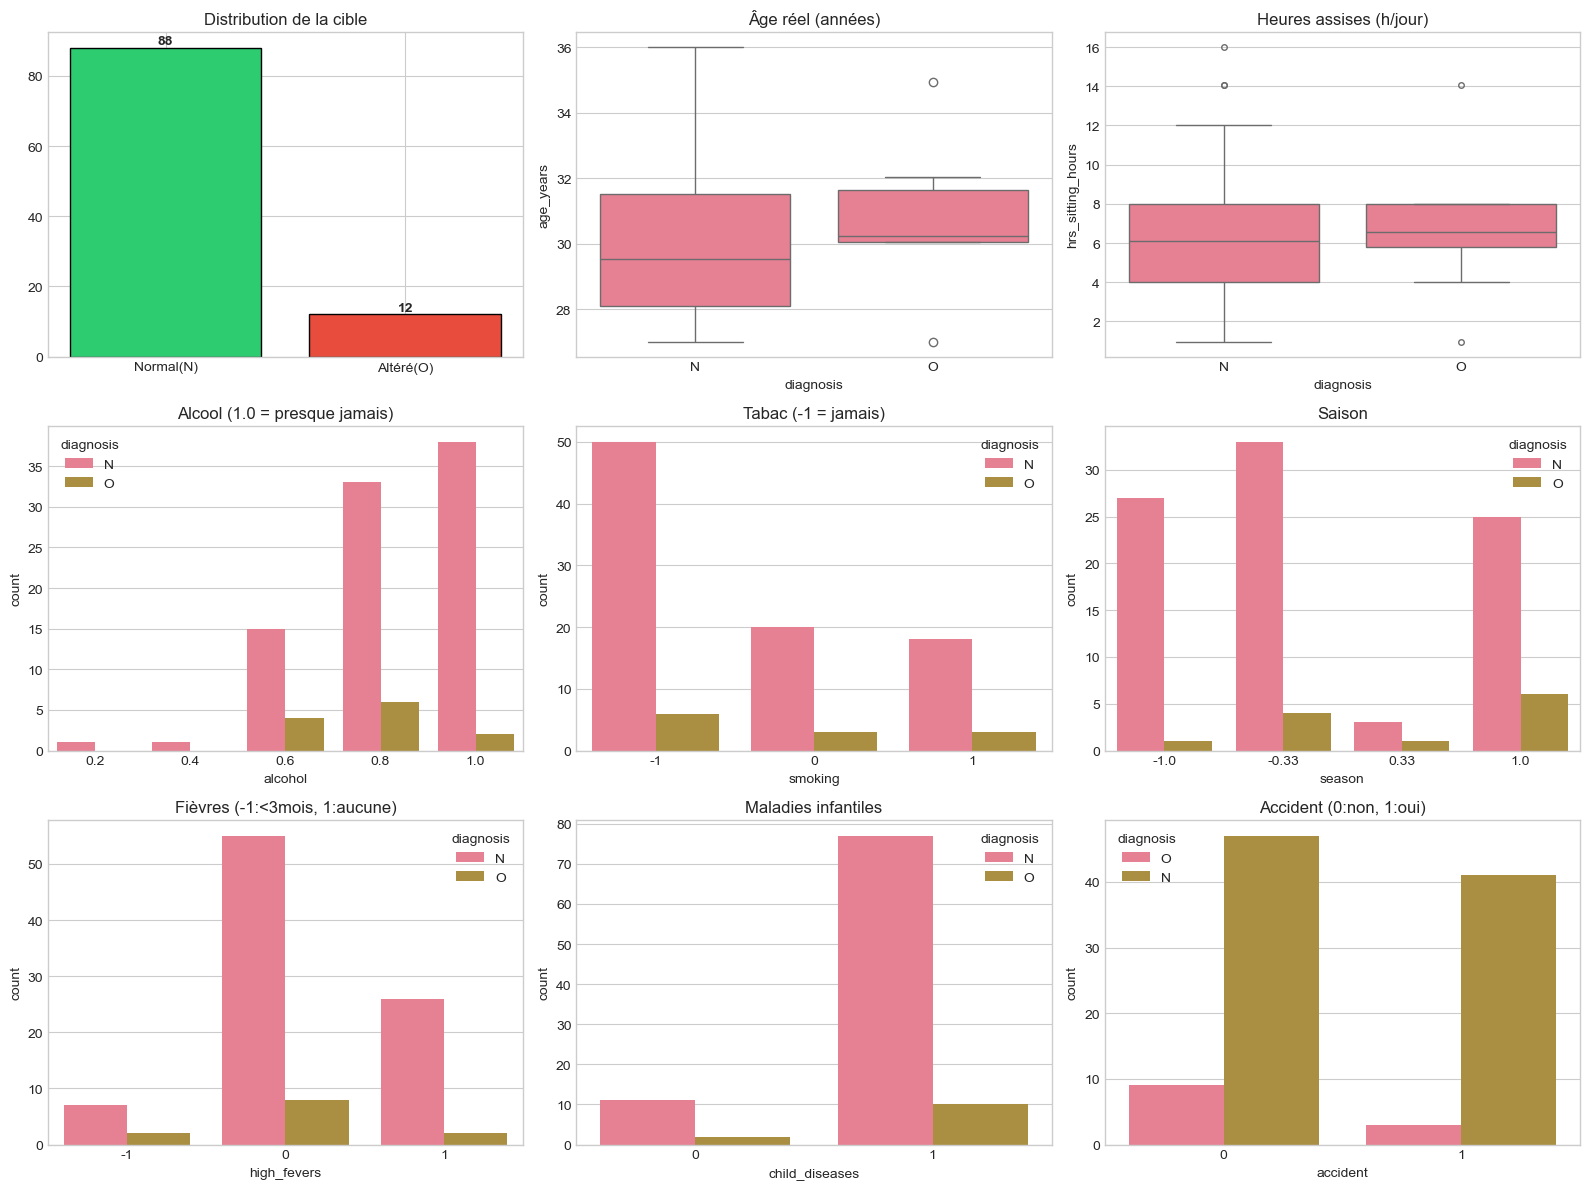

In [14]:
# configuration des graphiques 
fig, axes = plt.subplots( 3,3,figsize=(16,12) )

#1 cible 
cnt = df['diagnosis'].value_counts().reindex(["N","O"])
axes[0,0].bar(['Normal(N)','Altéré(O)'],cnt.values , color=["#2ecc71","#e74c3c"], edgecolor='black')
axes[0,0].set_title('Distribution de la cible')
for i,v in enumerate(cnt.values):
    axes[0,0].text(i,v+1, str(v) , ha='center', fontweight='bold')
    
# 2 Âge réel vs diagnostique
sns.boxplot( data=df, x='diagnosis' , y= 'age_years' , ax= axes[0,1] )
axes[0,1].set_title("Âge réel (années)")

#3 Heures assises vs diag
sns.boxplot(data=df , x='diagnosis', y='hrs_sitting_hours', 
            fliersize = 4 , # afficher outlier
            ax= axes[0,2] )
axes[0,2].set_title("Heures assises (h/jour)")

# 4 Alcool ( 1.0 = sobre)
sns.countplot(data=df, x="alcohol", hue="diagnosis", ax=axes[1,0])
axes[1,0].set_title("Alcool (1.0 = presque jamais)")

# 5 Tabac (-1 = jamais)
sns.countplot(data=df, x="smoking", hue="diagnosis", ax=axes[1,1])
axes[1,1].set_title("Tabac (-1 = jamais)")

# 6 Saison
sns.countplot(data=df, x="season", hue="diagnosis", ax=axes[1,2])
axes[1,2].set_title("Saison")

# 7 high_fevers
sns.countplot(data=df, x="high_fevers", hue="diagnosis", ax=axes[2,0])
axes[2,0].set_title("Fièvres (-1:<3mois, 1:aucune)")

# 8 child_diseases
sns.countplot(data=df, x="child_diseases", hue="diagnosis", ax=axes[2,1])
axes[2,1].set_title("Maladies infantiles")

# 9 accidents + chirurgie
sns.countplot(data=df, x="accident", hue="diagnosis", ax=axes[2,2])
axes[2,2].set_title("Accident (0:non, 1:oui)")

plt.tight_layout()
plt.show()            

###  Corrélations

Sur 100 observations et des variables majoritairement ordinales, la **matrice de Pearson** est un indicateur grossier (pas de vraie continuité). 
Elle reste utile pour repérer de fortes colinéarités éventuelles.

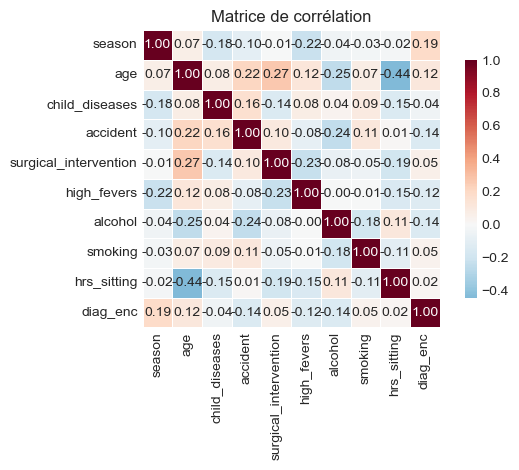

Corrélations avec la cible (Pearson) :
season                   0.192
alcohol                 -0.145
accident                -0.141
high_fevers             -0.121
age                      0.115
surgical_intervention    0.054
smoking                  0.046
child_diseases          -0.040
hrs_sitting              0.023
Name: diag_enc, dtype: float64


In [16]:
# matrice de corrélation

df_num = df.drop(columns= ["age_years","hrs_sitting_hours"]).copy()
df_num["diag_enc"] = LabelEncoder().fit_transform(df_num['diagnosis']) # je convertion en categorielle binaire 0,1 

corr = df_num.drop(columns="diagnosis").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, square=True, linewidths=0.5,
            cbar_kws={"shrink": .8})
plt.title("Matrice de corrélation")
plt.tight_layout(); plt.show()

print("Corrélations avec la cible (Pearson) :")
print(corr["diag_enc"].drop("diag_enc").sort_values(key=abs, ascending=False).round(3))

## 3. Préparation X / y

Cible encodée `N→0`, `O→1`. Pas de One-Hot : les ordinales gardent leur ordre.
On distinguera à l'évaluation les modèles **sensibles au scaling** (LogReg, SVM, KNN) des **arbres**.

In [18]:
# x/y 
x= df.drop( columns=["diagnosis", "age_years", "hrs_sitting_hours"] )
y = LabelEncoder().fit_transform(df['diagnosis']) # N=0, O=1

print(f"X: {x.shape}")
print(f"y : {np.bincount(y)}  → classe 0={np.bincount(y)[0]}, classe 1={np.bincount(y)[1]}")
neg, pos = np.bincount(y)

scale_pos_weight = neg / pos
print(f"scale_pos_weight (XGB) = {scale_pos_weight:.2f}")
print(f"Baseline 'tout Normal' = {neg/len(y):.1%} d'accuracy → trompeur !")

X: (100, 9)
y : [88 12]  → classe 0=88, classe 1=12
scale_pos_weight (XGB) = 7.33
Baseline 'tout Normal' = 88.0% d'accuracy → trompeur !


### Modélisation : Cross-validation stratifiée

**Baseline DummyClassifier obligatoire** : avec 88% de N, un modèle naïf atteint 88% d'accuracy sans rien apprendre.
Pipeline `StandardScaler → modèle` pour LogReg, SVM, KNN. 
`class_weight='balanced'` partout. Évaluation par **StratifiedKFold(5)**.

## Modèles et CV

In [40]:
# strafication et modèles

cv = StratifiedKFold( n_splits= 5, shuffle= True , random_state = SEED)

def pipe(clf):
    return Pipeline([("scaler", StandardScaler()) , ("clf",clf)])

models = {
     "Dummy (baseline)":  DummyClassifier(strategy="most_frequent", random_state= SEED),
     "LogReg (scaled)":   pipe( LogisticRegression( class_weight="balanced" , max_iter= 200 , random_state= SEED) ),
     "RandomForest":      RandomForestClassifier( n_estimators = 200 , class_weight= "balanced" , random_state= SEED , n_jobs= -1 ),
     "GradientBoosting":  GradientBoostingClassifier( n_estimators= 100 , random_state= SEED) ,
     "SVM (scaled)":      pipe( SVC( class_weight = "balanced" , probability = True , random_state= SEED) ),
     "KNN (k=5, scaled)": pipe(KNeighborsClassifier(n_neighbors=5)),
     "XGBoost":           xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                                             max_depth=3,
                                             scale_pos_weight=scale_pos_weight,
                                             random_state=SEED,
                                             eval_metric="logloss",
                                             verbosity=0)
}

scoring = ["accuracy", "precision", "recall", "f1",
           "roc_auc", "balanced_accuracy"]

print("Cross-validation (5 folds stratifiés)...\n")

rows = []

for name, mdl in models.items() : 
    sc = cross_validate ( mdl, x, y , cv=cv , scoring= scoring , n_jobs= -1 ) 
    rows.append({
        "Modèle": name ,
        "Accuracy" : sc['test_accuracy'].mean(),
        "Bal.Acc":   sc["test_balanced_accuracy"].mean(),
        "Precision": sc["test_precision"].mean(),
        "Recall":    sc["test_recall"].mean(),
        "F1":        sc["test_f1"].mean(),
        "AUC-ROC":   sc["test_roc_auc"].mean()
    })
cv_results = pd.DataFrame(rows).set_index("Modèle").round(3)
cv_results= cv_results.sort_values("AUC-ROC", ascending = False)
print(cv_results.to_string())

print("\n  n=100 → variance élevée. Prioriser AUC/F1 sur l'accuracy brute.")


Cross-validation (5 folds stratifiés)...

                   Accuracy  Bal.Acc  Precision  Recall     F1  AUC-ROC
Modèle                                                                 
RandomForest           0.86    0.516      0.200   0.067  0.100    0.690
XGBoost                0.78    0.498      0.067   0.133  0.089    0.665
LogReg (scaled)        0.68    0.601      0.210   0.500  0.291    0.639
KNN (k=5, scaled)      0.86    0.488      0.000   0.000  0.000    0.626
GradientBoosting       0.85    0.538      0.133   0.133  0.133    0.599
SVM (scaled)           0.82    0.592      0.233   0.300  0.259    0.596
Dummy (baseline)       0.88    0.500      0.000   0.000  0.000    0.500

  n=100 → variance élevée. Prioriser AUC/F1 sur l'accuracy brute.


## 4. Optimisation des hyperparamètres

### GridSearchCV sur GradientBoosting (robuste, interprétable, gère bien les petits datasets).

In [46]:
# tuning 

param_grid = {
    "n_estimators": [50,100,200],
    "learning_rate": [0.01, 0.05 , 0.1],
    "max_depth": [2,3,4],
    "subsample": [0.8, 1.0]
}

grid = GridSearchCV(
    GradientBoostingClassifier(random_state= SEED),
    param_grid, cv=cv, scoring= "roc_auc", n_jobs= -1 )

grid.fit(x,y)

print(f" Meilleurs paramètres : {grid.best_params_}")
print(f"Meilleure AUC (CV)   : {grid.best_score_:.3f}")
best_model = grid.best_estimator_

 Meilleurs paramètres : {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 200, 'subsample': 1.0}
Meilleure AUC (CV)   : 0.710


### Évaluation hold-out (indicatif)

Split 80/20 stratifié. **n_test = 20 → très instable**, ne pas surinterpréter.
La CV reste la référence de performance.

ÉVALUATION HOLD-OUT (n_test=20) — indicatif
Accuracy          : 0.900
Balanced accuracy : 0.500
Precision (Altéré): 0.000
Recall (Altéré)   : 0.000
F1 (Altéré)       : 0.000
AUC-ROC           : 0.417

Rapport détaillé :
              precision    recall  f1-score   support

      Normal       0.90      1.00      0.95        18
      Altéré       0.00      0.00      0.00         2

    accuracy                           0.90        20
   macro avg       0.45      0.50      0.47        20
weighted avg       0.81      0.90      0.85        20



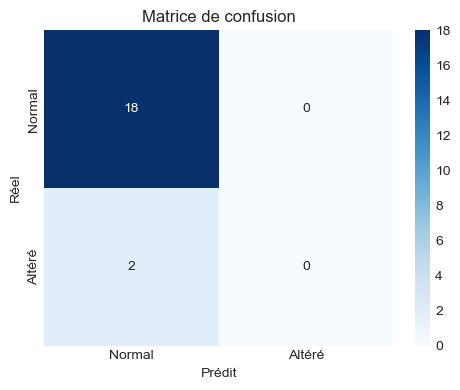

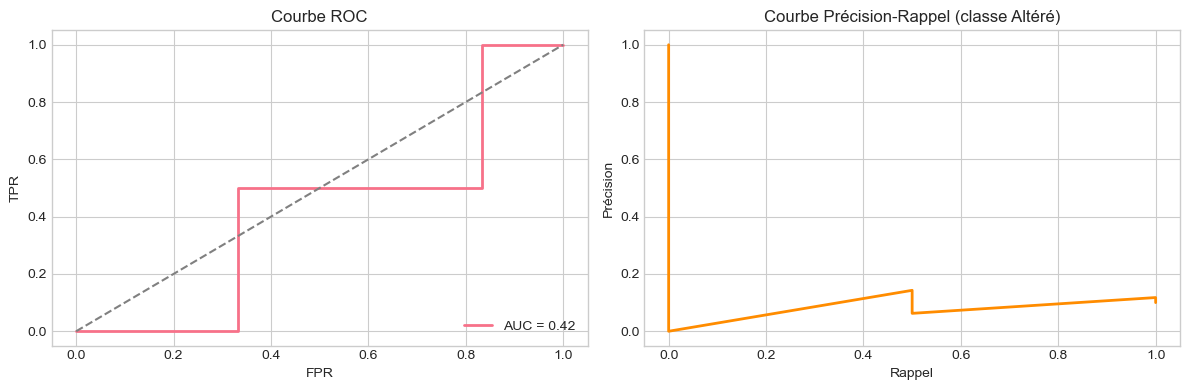

In [57]:
# hold out 

x_tr, x_te , y_tr , y_te = train_test_split( x, y, test_size= 0.2 , random_state= SEED)
best_model.fit(x_tr, y_tr)
y_pred = best_model.predict(x_te)
y_proba = best_model.predict_proba(x_te)[:,1]

print("=" * 55)
print(f"ÉVALUATION HOLD-OUT (n_test={len(y_te)}) — indicatif")
print("=" * 55)
print(f"Accuracy          : {accuracy_score(y_te, y_pred):.3f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_te, y_pred):.3f}")
print(f"Precision (Altéré): {precision_score(y_te, y_pred, zero_division=0):.3f}")
print(f"Recall (Altéré)   : {recall_score(y_te, y_pred, zero_division=0):.3f}")
print(f"F1 (Altéré)       : {f1_score(y_te, y_pred, zero_division=0):.3f}")
print(f"AUC-ROC           : {roc_auc_score(y_te, y_proba):.3f}")

print("\nRapport détaillé :")
print(classification_report(y_te, y_pred, target_names=["Normal","Altéré"],
                            zero_division=0))

# Matrice de confusion
cm = confusion_matrix(y_te, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal","Altéré"],
            yticklabels=["Normal","Altéré"])
plt.title("Matrice de confusion")
plt.ylabel("Réel"); plt.xlabel("Prédit")
plt.tight_layout(); plt.show()

# ROC + PR
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
fpr, tpr, _ = roc_curve(y_te, y_proba)
ax[0].plot(fpr, tpr, lw=2, label=f"AUC = {auc(fpr, tpr):.2f}")
ax[0].plot([0,1],[0,1],'--', color='grey')
ax[0].set_title("Courbe ROC")
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_te, y_proba)
ax[1].plot(rec, prec, lw=2, color="darkorange")
ax[1].set_title("Courbe Précision-Rappel (classe Altéré)")
ax[1].set_xlabel("Rappel"); ax[1].set_ylabel("Précision")
plt.tight_layout(); plt.show()


## 5. Importance des features

Guard `hasattr(feature_importances_)` pour éviter le crash sur LogReg/SVM/KNN.
SHAP `TreeExplainer` uniquement si le modèle final est un arbre.

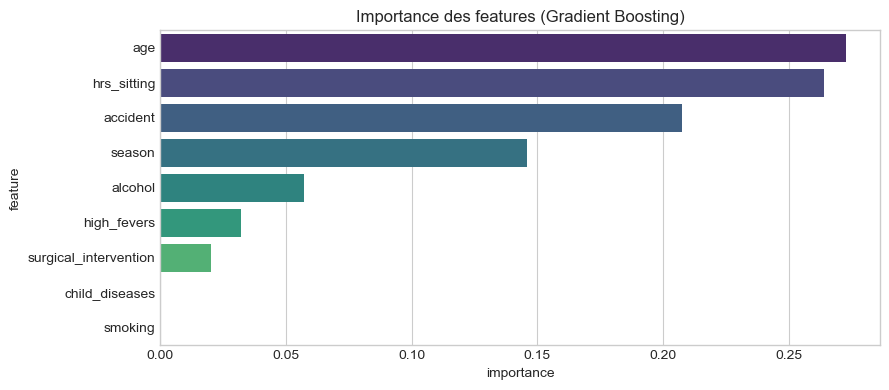

              feature  importance
                  age      0.2727
          hrs_sitting      0.2642
             accident      0.2078
               season      0.1460
              alcohol      0.0570
          high_fevers      0.0322
surgical_intervention      0.0201
       child_diseases      0.0000
              smoking      0.0000


In [67]:
# feature importance 

feature_names = X.columns.tolist()

if hasattr(best_model, "feature_importances_"):
    fi = pd.DataFrame({
        "feature":    feature_names,
        "importance": best_model.feature_importances_,
    }).sort_values("importance", ascending=False)

    plt.figure(figsize=(9, 4))
    sns.barplot(data=fi, x="importance", y="feature", palette="viridis")
    plt.title("Importance des features (Gradient Boosting)")
    plt.tight_layout(); plt.show()

    print(fi.round(4).to_string(index=False))
else:
    print(" Modèle sans 'feature_importances_' → importance non disponible directement.")

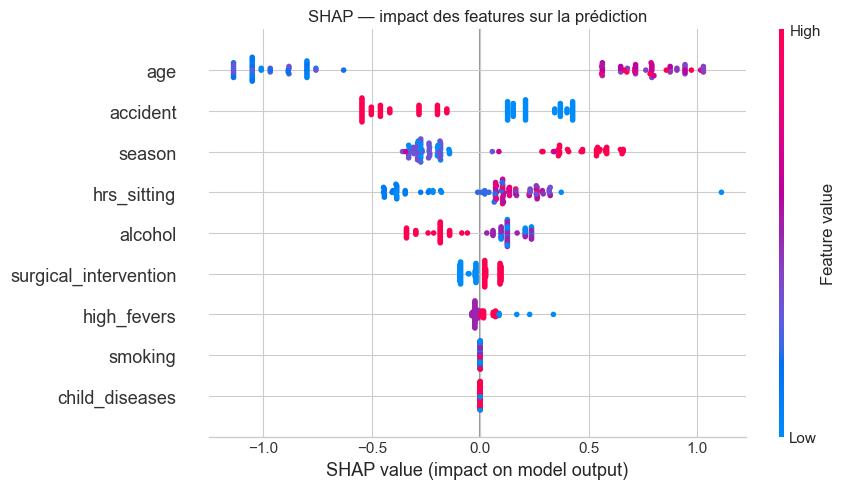

In [71]:
# 13. shap (guard)

try:
    import shap
    SHAP_OK = True
except ImportError:
    SHAP_OK = False
    print("shap non installé : pip install shap")
    
if SHAP_OK and hasattr(best_model, "feature_importances_"):
    explainer   = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X)

    plt.figure()
    shap.summary_plot(shap_values, X, feature_names=feature_names,
                      show=False, plot_size=(9, 5))
    plt.title("SHAP — impact des features sur la prédiction")
    plt.tight_layout(); plt.show()
else:
    print("SHAP non exécuté (module absent ou modèle non-arbre).")

### fonction de prédiction : unités réelles

Accepte `age` en **années** et `hrs_sitting` en **heures**.
La normalisation [0,1] est faite en interne. 
Avertit si les valeurs sont hors plage d'entraînement.

In [73]:

#  prédiction en unités réelles

def predict_fertility(season, age_years, child_diseases, accident,
                      surgical_intervention, high_fevers, alcohol,
                      smoking, hrs_sitting_hours):
    """
    Prédit la fertilité masculine à partir de valeurs réelles.

    Paramètres
    ----------
    season                 : -1 | -0.33 | 0.33 | 1
    age_years              : 27–36 (plage d'entraînement)
    child_diseases         : 0 | 1
    accident               : 0 | 1
    surgical_intervention  : 0 | 1
    high_fevers            : -1 | 0 | 1
    alcohol                : 0.2 | 0.4 | 0.6 | 0.8 | 1.0  (1.0 = presque jamais)
    smoking                : -1 | 0 | 1
    hrs_sitting_hours      : 0–16
    """
    if not (18 <= age_years <= 36):
        print(f"  age={age_years} hors plage [18-36]")
    if not (0 <= hrs_sitting_hours <= 16):
        print(f" hrs={hrs_sitting_hours} hors plage [0-16]")

    age_norm = (age_years - 18) / 18
    hrs_norm = hrs_sitting_hours / 16

    sample = pd.DataFrame([{
        "season": season, "age": age_norm,
        "child_diseases": child_diseases, "accident": accident,
        "surgical_intervention": surgical_intervention,
        "high_fevers": high_fevers, "alcohol": alcohol,
        "smoking": smoking, "hrs_sitting": hrs_norm,
    }])[X.columns]

    p_altered = best_model.predict_proba(sample)[0, 1]
    pred = "Altéré" if p_altered >= 0.5 else "Normal"
    return {
        "prediction":            pred,
        "probability_altered":   float(p_altered),
        "probability_normal":    float(1 - p_altered),
    }

# Exemple
ex = predict_fertility(
    season=-0.33, age_years=32, child_diseases=0, accident=0,
    surgical_intervention=0, high_fevers=0, alcohol=0.8,
    smoking=-1, hrs_sitting_hours=8,
)
print(" Exemple de prédiction :")
for k, v in ex.items():
    print(f"  {k:22s} : {v if isinstance(v, str) else f'{v:.1%}'}")

 Exemple de prédiction :
  prediction             : Normal
  probability_altered    : 23.5%
  probability_normal     : 76.5%


## 6. Réentraînement final & synthèse

Le modèle est réentraîné sur 100% des données pour le déploiement.
**Mais les métriques honnêtes sont celles de la CV stratifiée** (celles du tableau §9).

In [76]:
#Réentraînement final & synthèse

best_model.fit(X, y)
print(" Modèle final réentraîné sur l'intégralité du dataset (n=100).")

print("\n" + "=" * 55)
print("SYNTHÈSE DU PROJET")
print("=" * 55)
print(f"Dataset           : 100 obs × 9 features, 0 manquant")
print(f"Cible             : {neg} Normal / {pos} Altéré")
print(f"Baseline (naïve)  : {neg/len(y):.1%} accuracy (trompeur !)")
print(f"Meilleur modèle   : Gradient Boosting tuné")
print(f"Meilleure AUC CV  : {grid.best_score_:.3f}")

print("\n LIMITES :")
print("  • n=100 → variance élevée, validation externe indispensable")
print("  • Âge limité à 27-36 ans (18-26 absent du dataset)")
print("  • Classe Altéré = 12% → recall structurellement limité")
print("  • Aucune donnée biologique (hormones, spermogramme détaillé)")

print("\n FORCES :")
print("  • Pipeline reproductible (StratifiedKFold, class_weight)")
print("  • Interprétation en unités réelles (années, heures)")
print("  • Sémantique UCI correctement documentée")
print("  • Baseline incluse → résultats honnêtes")

 Modèle final réentraîné sur l'intégralité du dataset (n=100).

SYNTHÈSE DU PROJET
Dataset           : 100 obs × 9 features, 0 manquant
Cible             : 88 Normal / 12 Altéré
Baseline (naïve)  : 88.0% accuracy (trompeur !)
Meilleur modèle   : Gradient Boosting tuné
Meilleure AUC CV  : 0.710

 LIMITES :
  • n=100 → variance élevée, validation externe indispensable
  • Âge limité à 27-36 ans (18-26 absent du dataset)
  • Classe Altéré = 12% → recall structurellement limité
  • Aucune donnée biologique (hormones, spermogramme détaillé)

 FORCES :
  • Pipeline reproductible (StratifiedKFold, class_weight)
  • Interprétation en unités réelles (années, heures)
  • Sémantique UCI correctement documentée
  • Baseline incluse → résultats honnêtes


In [78]:
# Export des figures pour le README
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc

ASSETS = "assets"
os.makedirs(ASSETS, exist_ok=True)

def save(fig, name):
    """Sauvegarde en PNG 150 dpi puis ferme la figure."""
    fig.savefig(os.path.join(ASSETS, name), dpi=150, bbox_inches="tight")
    plt.close(fig)
    print("sauvegardé :", name)

# 01. Distribution de la cible
cnt = df["diagnosis"].value_counts().reindex(["N", "O"])
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Normal (N)", "Altéré (O)"], cnt.values,
       color=["#2ecc71", "#e74c3c"], edgecolor="black")
for i, v in enumerate(cnt.values):
    ax.text(i, v + 1, str(v), ha="center", fontweight="bold")
ax.set_title("Distribution de la cible")
save(fig, "01_target_distribution.png")

# 02. Âge réel selon le diagnostic
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=df, x="diagnosis", y="age_years", order=["N", "O"], ax=ax)
sns.stripplot(data=df, x="diagnosis", y="age_years", order=["N", "O"],
              color="black", alpha=0.4, size=3, ax=ax)
ax.set_title("Âge réel selon le diagnostic")
ax.set_ylabel("Âge (années)")
save(fig, "02_age_vs_diagnosis.png")

# 03. Matrice de corrélation (cible encodée N=0, O=1)
df_num = df.drop(columns=["age_years", "hrs_sitting_hours"]).copy()
df_num["diag_enc"] = (df_num["diagnosis"] == "O").astype(int)
corr_m = df_num.drop(columns="diagnosis").corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Matrice de corrélation")
save(fig, "03_correlation_matrix.png")

# 04. Comparaison des modèles (CV stratifiée)
res = cv_results.sort_values("AUC-ROC")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(res.index, res["AUC-ROC"], color="#8E44AD")
axes[0].axvline(0.5, color="grey", linestyle="--", label="Hasard (0,5)")
axes[0].axvline(grid.best_score_, color="#e74c3c", linestyle=":",
                label=f"GB optimisé ({grid.best_score_:.3f}, optimiste)")
axes[0].set_title("AUC-ROC (CV 5 folds)")
axes[0].legend(loc="lower right", fontsize=8)
axes[1].barh(res.index, res["Bal.Acc"], color="#3498db")
axes[1].axvline(0.5, color="grey", linestyle="--")
axes[1].set_title("Balanced accuracy (CV 5 folds)")
fig.tight_layout()
save(fig, "04_model_comparison.png")

# Hold-out refait avec la même graine que le notebook
x_tr, x_te, y_tr, y_te = train_test_split(x, y, test_size=0.2, random_state=SEED)
holdout_model = clone(best_model).fit(x_tr, y_tr)
y_pred = holdout_model.predict(x_te)
y_proba = holdout_model.predict_proba(x_te)[:, 1]

# 05. Matrice de confusion
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_te, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Altéré"], yticklabels=["Normal", "Altéré"], ax=ax)
ax.set_title(f"Matrice de confusion (hold-out, n={len(y_te)})")
ax.set_ylabel("Réel")
ax.set_xlabel("Prédit")
save(fig, "05_confusion_matrix.png")

# 06. Courbe ROC du hold-out
fpr, tpr, _ = roc_curve(y_te, y_proba)
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot(fpr, tpr, lw=2, label=f"AUC = {auc(fpr, tpr):.2f}")
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("Courbe ROC (hold-out, indicatif)")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.legend(loc="lower right")
save(fig, "06_roc_curve.png")

# Modèle final sur 100 lignes pour importance et SHAP
final_model = clone(best_model).fit(x, y)

# 07. Importance des variables
fi = (pd.DataFrame({"feature": x.columns,
                    "importance": final_model.feature_importances_})
        .sort_values("importance", ascending=False))
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=fi, x="importance", y="feature", palette="viridis", ax=ax)
ax.set_title("Importance des variables (Gradient Boosting, impureté)")
save(fig, "07_feature_importance.png")

# 08. SHAP
sv = shap.TreeExplainer(final_model).shap_values(x)
if isinstance(sv, list):
    sv = sv[1]
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, 1]
plt.figure()
shap.summary_plot(sv, x, show=False)
fig = plt.gcf()
fig.set_size_inches(9, 5)
plt.title("SHAP : impact des variables sur la prédiction")
save(fig, "08_shap_summary.png")

sauvegardé : 01_target_distribution.png
sauvegardé : 02_age_vs_diagnosis.png
sauvegardé : 03_correlation_matrix.png
sauvegardé : 04_model_comparison.png
sauvegardé : 05_confusion_matrix.png
sauvegardé : 06_roc_curve.png
sauvegardé : 07_feature_importance.png
sauvegardé : 08_shap_summary.png
